## Dawn Andrei Pamesa
## TS31

## CHAID Decision Tree: Mushroom Dataset

Dataset: mushroom_demo_dataset.csv (500 mushrooms, 8 categorical features, class = edible or poisonous)

Install CHAID

In [1]:
!pip install -q CHAID

Imports

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import chi2_contingency
from sklearn.model_selection import train_test_split
from CHAID import Tree

Load Data

In [3]:
df = pd.read_csv("mushroom_demo_dataset.csv")
df.head()

,class,cap_shape,cap_surface,cap_color,bruises,odor,gill_size,stalk_color,habitat
0,edible,bell,fibrous,yellow,no,anise,broad,buff,urban
1,edible,knobbed,fibrous,white,no,almond,broad,brown,grasses
2,poisonous,knobbed,fibrous,white,yes,pungent,narrow,buff,meadows
3,poisonous,bell,grooves,yellow,no,foul,narrow,buff,grasses
4,poisonous,convex,fibrous,brown,no,almond,narrow,yellow,leaves


In [4]:
print("Shape :", df.shape)

Shape : (500, 9)


In [5]:
print("Missing values :", df.isnull().sum().sum())

Missing values : 0


In [6]:
df['class'].value_counts()

class
poisonous    353
edible       147
Name: count, dtype: int64

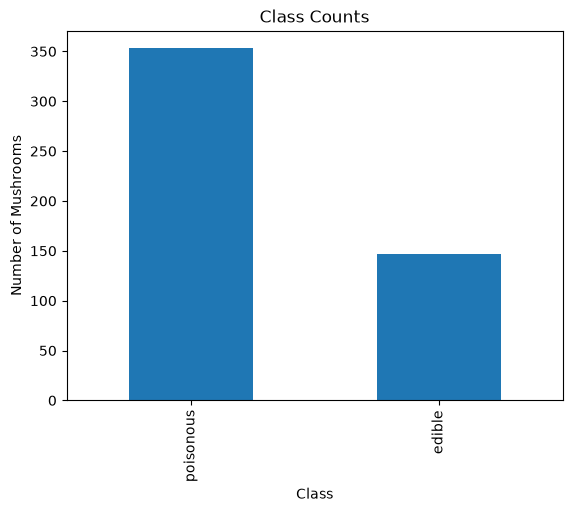

In [7]:
df['class'].value_counts().plot(kind='bar')
plt.title("Class Counts")
plt.xlabel("Class")
plt.ylabel("Number of Mushrooms")
plt.show()

Features and Target

In [8]:
inputs = df.drop('class', axis='columns')

In [9]:
target = df['class']

Train and Test Split

In [10]:
X_train, X_test, y_train, y_test = train_test_split(inputs, target, test_size=0.3, random_state=0)

In [11]:
print("Train shape :", X_train.shape)
print("Test shape  :", X_test.shape)

Train shape : (350, 8)
Test shape  : (150, 8)


How CHAID Picks a Split

In [12]:
table = pd.crosstab(X_train['gill_size'], y_train)
table

class,edible,poisonous
gill_size,,
broad,93,79
narrow,9,169


In [13]:
chi2, p, dof, expected = chi2_contingency(table)
print("Chi-square :", chi2)
print("p-value    :", p)

Chi-square : 99.40508759615135
p-value    : 2.0579323528460165e-23


In [14]:
for col in X_train.columns:
    chi2, p, dof, expected = chi2_contingency(pd.crosstab(X_train[col], y_train))
    print(col, ": p-value =", p)

cap_shape : p-value = 0.399828725358571
cap_surface : p-value = 0.1589059755254941
cap_color : p-value = 0.03617266244366229
bruises : p-value = 0.7241770005484875
odor : p-value = 1.4173446593619997e-14
gill_size : p-value = 2.0579323528460165e-23


stalk_color : p-value = 0.07892571223276529
habitat : p-value = 0.6213314508183312


Build the CHAID Tree

In [15]:
train_df = X_train.copy()
train_df['class'] = y_train

In [16]:
independent_variables = dict.fromkeys(X_train.columns, 'nominal')

In [17]:
chaid_tree = Tree.from_pandas_df(train_df, independent_variables, 'class',
                                 alpha_merge=0.05, max_depth=3,
                                 min_parent_node_size=30, min_child_node_size=10)

Tree Output

In [18]:
chaid_tree.print_tree()

([], {'edible': 102.0, 'poisonous': 248.0}, (gill_size, p=6.252100528719342e-24, score=101.76481016114901, groups=[['broad'], ['narrow']]), dof=1))
|-- (['broad'], {'edible': 93.0, 'poisonous': 79.0}, (odor, p=1.922617960144345e-33, score=145.21986615483414, groups=[['almond', 'anise', 'none'], ['foul', 'pungent']]), dof=1))
|   |-- (['almond', 'anise', 'none'], {'edible': 88.0, 'poisonous': 2.0}, (stalk_color, p=0.043114446783075286, score=4.090909090909092, groups=[['brown', 'gray', 'pink', 'red', 'yellow'], ['buff', 'white']]), dof=1))
|   |   |-- (['brown', 'gray', 'pink', 'red', 'yellow'], {'edible': 60.0, 'poisonous': 0}, <Invalid Chaid Split> - the max depth has been reached)
|   |   +-- (['buff', 'white'], {'edible': 28.0, 'poisonous': 2.0}, <Invalid Chaid Split> - the minimum parent node size threshold has been reached)
|   +-- (['foul', 'pungent'], {'edible': 5.0, 'poisonous': 77.0}, (stalk_color, p=0.07176788763136771, score=10.125074925074925, groups=[['brown', 'gray'], ['b

Train Accuracy

In [19]:
print("Train accuracy :", chaid_tree.accuracy())

Train accuracy : 0.9542857142857143


Predict the Test Set

In [20]:
predictions = []
for i in range(len(X_test)):
    row = X_test.iloc[i]
    node = chaid_tree.tree_store[0]
    while node.split_variable is not None:
        value = row[node.split_variable]
        children = [n for n in chaid_tree.tree_store if n.parent == node.node_id and value in n.choices]
        if len(children) == 0:
            break
        node = children[0]
    predictions.append(max(node.members, key=node.members.get))

In [21]:
y_pred = pd.Series(predictions, index=y_test.index)

In [22]:
print("Test accuracy :", (y_pred == y_test).mean())

Test accuracy : 0.9133333333333333


In [23]:
pd.crosstab(y_test, y_pred, rownames=['Actual'], colnames=['Predicted'])

Predicted,edible,poisonous
Actual,,
edible,37,8
poisonous,5,100


Predict a New Mushroom

In [24]:
x_new = pd.Series({'cap_shape': 'bell', 'cap_surface': 'smooth', 'cap_color': 'white', 'bruises': 'yes',
                  'odor': 'none', 'gill_size': 'broad', 'stalk_color': 'red', 'habitat': 'leaves'})

In [25]:
node = chaid_tree.tree_store[0]
while node.split_variable is not None:
    value = x_new[node.split_variable]
    children = [n for n in chaid_tree.tree_store if n.parent == node.node_id and value in n.choices]
    if len(children) == 0:
        break
    node = children[0]
print("Prediction :", max(node.members, key=node.members.get))

Prediction : edible


Wrap-Up

CHAID picks each split by running a chi-square test of every feature against the class and taking the feature with the smallest p-value. On the training data that was gill_size (p = 2.06e-23), followed by odor on the broad-gill branch. With max_depth = 3, the tree got 95.4% accuracy on the training set and 91.3% on the test set. Of the 150 test mushrooms, 8 edible ones were predicted poisonous and 5 poisonous ones were predicted edible. The 5 poisonous mushrooms predicted as edible are the more serious mistake.